# Etapa 1: corrida 2D com um drone "ponto de massa"

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/henriquecorneau/dronerl/blob/main/notebooks/01_corrida_2d_ponto_de_massa.ipynb)

Neste primeiro notebook vamos montar **do zero** um problema de corrida de drone e resolvê-lo com
Reinforcement Learning usando o **PPO** do Stable-Baselines3.

Para focar nos conceitos de RL, o "drone" aqui é bem simplificado: um **ponto de massa em 2D**
que escolhe a própria aceleração. Nas próximas etapas trocamos isso por um quadrotor 3D de verdade,
mas **a estrutura do ambiente, da recompensa e do treino continua a mesma**.

**Ao final você vai saber:**
1. Os conceitos básicos de RL (estado, ação, recompensa, política, retorno, desconto) aplicados a um drone.
2. Como escrever um ambiente compatível com **Gymnasium** (`reset`, `step`, `observation_space`, `action_space`).
3. Como detectar a passagem por um portão com geometria simples.
4. Como desenhar uma **função de recompensa** para corrida.
5. Como treinar, monitorar, avaliar, salvar e carregar um agente **PPO**.
6. Como **visualizar o aprendizado** com vários drones: os drones de treino e uma "corrida de fantasmas" entre versões da política.

⏱️ O treino leva cerca de 1 minuto numa CPU de desktop e de 3 a 5 minutos no Colab.

## 0. Preparando o ambiente

No Colab, a célula abaixo instala o Stable-Baselines3 e o Gymnasium (o PyTorch já vem instalado).
Localmente, use o `requirements.txt` do repositório dentro de um ambiente virtual (veja o README).

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q "stable-baselines3[extra]>=2.3" "gymnasium>=1.0"

In [2]:
import json
import time
from dataclasses import dataclass
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import stable_baselines3 as sb3
import torch
from gymnasium import spaces

print(f"gymnasium {gym.__version__} | stable-baselines3 {sb3.__version__} | torch {torch.__version__}")

gymnasium 1.4.0 | stable-baselines3 2.9.2 | torch 2.15.0+cu132


## 1. Reinforcement Learning em 3 minutos

Em RL, um **agente** aprende por tentativa e erro interagindo com um **ambiente**:

```
            ação a_t (aceleração desejada)
   ┌────────┐ ─────────────────────────────▶ ┌─────────────┐
   │ Agente │                                │  Ambiente   │
   │ π(a|o) │ ◀───────────────────────────── │ (física +   │
   └────────┘   observação o_{t+1},          │   pista)    │
                recompensa r_{t+1}           └─────────────┘
```

| Conceito | Símbolo | No nosso drone |
|---|---|---|
| Estado | $s_t$ | posição e velocidade do drone, qual é o próximo portão |
| Observação | $o_t$ | o que a rede neural "vê": velocidade, posição relativa dos próximos portões, última ação |
| Ação | $a_t$ | aceleração desejada em x e y, normalizada em $[-1, 1]$ |
| Recompensa | $r_t$ | um número a cada passo: + por se aproximar do portão, + ao atravessá-lo, − ao bater |
| Episódio | | uma tentativa: do início até completar as voltas, bater ou estourar o tempo |
| Política | $\pi_\theta(a \mid o)$ | uma rede neural com pesos $\theta$ que escolhe a ação |

O objetivo é encontrar a política que maximiza o **retorno descontado** esperado:

$$G_t = \sum_{k=0}^{\infty} \gamma^k \, r_{t+k+1}, \qquad 0 < \gamma < 1$$

O fator de desconto $\gamma$ faz recompensas futuras valerem menos que as imediatas.
Para corrida isso é ótimo: **chegar ao portão mais cedo vale mais**, então o agente aprende a ser rápido
mesmo que a gente nunca diga explicitamente "seja rápido".

Uma regra prática: o "horizonte" efetivo é de aproximadamente $1/(1-\gamma)$ passos.
Com $\gamma = 0.99$ e passos de 0.05 s, o agente "enxerga" uns 100 passos, ou seja, cerca de 5 s à frente.

## 2. Configuração do experimento

Todos os hiperparâmetros ficam num único dicionário `CONFIG`. Assim fica fácil:
- mudar um valor e rodar de novo sem caçar números espalhados pelo código;
- salvar a configuração junto com o modelo treinado (reprodutibilidade).

Também fixamos a **seed** (semente aleatória). RL é muito sensível a aleatoriedade, então
sem seed fixa dois treinos "iguais" podem dar resultados bem diferentes.

In [3]:
CONFIG = {
    "seed": 42,
    "env": {
        "dt": 0.05,                 # passo de simulação [s] (20 Hz)
        "a_max": 15.0,              # aceleração máxima [m/s²] (~1.5 g)
        "k_drag": 0.5,              # arrasto linear [1/s] -> velocidade terminal = a_max/k_drag = 30 m/s
        "n_laps": 2,                # voltas para completar a corrida
        "max_time": 40.0,           # tempo limite do episódio [s]
        "arena_half_size": [30.0, 20.0],   # sair de |x|>30 ou |y|>20 conta como batida [m]
        "start_dist": 4.0,          # o drone começa parado a 4 m antes do 1º portão [m]
        "start_noise": 0.5,         # ruído na posição inicial [m]
        "random_start_gate": True,  # começar em portões aleatórios (ajuda a explorar a pista toda)
        "obs_pos_scale": 10.0,      # normalização das posições na observação [m]
        "obs_vel_scale": 10.0,      # normalização das velocidades na observação [m/s]
        "track": {"n_gates": 6, "a": 20.0, "b": 12.0, "width": 2.0, "frame": 0.5, "jitter": 0.0},
        "reward": {
            "progress": 1.0,        # por metro de aproximação do próximo portão
            "gate": 10.0,           # bônus por atravessar um portão
            "crash": 10.0,          # penalidade por bater
            "action": 0.01,         # penalidade por |a|²  (gasto de "energia")
            "smooth": 0.05,         # penalidade por |a_t - a_(t-1)|²  (comandos suaves)
        },
    },
    "ppo": {
        "n_steps": 512,             # passos coletados por ambiente antes de cada atualização
        "batch_size": 256,          # tamanho do mini-batch do gradiente
        "n_epochs": 10,             # quantas vezes reutilizamos cada lote de dados
        "gamma": 0.99,              # fator de desconto
        "gae_lambda": 0.95,         # suavização da estimativa de vantagem (GAE)
        "learning_rate": 3e-4,
        "clip_range": 0.2,          # o "clip" do PPO: limita o tamanho de cada atualização
        "ent_coef": 0.0,            # bônus de entropia (exploração extra)
    },
    "net_arch": [128, 128],         # camadas escondidas do ator e do crítico
    "n_envs": 8,                    # ambientes rodando em paralelo
    "total_timesteps": 300_000,
    "eval_freq": 10_000,            # avaliar a cada N passos (somando todos os ambientes)
    "viz": {
        "checkpoint_every": 25_000,         # salvar a política a cada N passos (p/ a corrida de fantasmas)
        "ghost_steps": [25_000, 50_000, 100_000, 200_000],   # checkpoints que vão correr juntos
        "record_fracs": [0.0, 0.1, 0.25, 0.5, 0.9],          # quando gravar os drones de treino (fração do treino)
        "record_window": 300,               # quantos passos gravar em cada momento (300 × 0.05 s = 15 s)
        "save_gifs": True,                  # salvar as animações como GIF em RUN_DIR
    },
}

In [4]:
from stable_baselines3.common.utils import set_random_seed

set_random_seed(CONFIG["seed"])     # fixa random, numpy e torch de uma vez

RUN_DIR = Path("runs") / f"etapa1_ppo_seed{CONFIG['seed']}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "config.json").write_text(json.dumps(CONFIG, indent=2))
print("Resultados serão salvos em", RUN_DIR.resolve())

Resultados serão salvos em /home/hen/Projects/dronerl/notebooks/runs/etapa1_ppo_seed42


## 3. A física: um drone como ponto de massa

Um quadrotor real acelera para os lados **inclinando o corpo** e apontando o empuxo para onde quer ir.
Nesta etapa abstraímos isso: o agente escolhe **diretamente a aceleração** $\mathbf{a}_{cmd}$ (em m/s²),
como se um controlador de baixo nível cuidasse da inclinação. Na Etapa 2 trocamos por empuxo + velocidades angulares.

O modelo, com um arrasto aerodinâmico linear simples:

$$\dot{\mathbf{v}} = \mathbf{a}_{cmd} - k_{drag}\,\mathbf{v}, \qquad \dot{\mathbf{p}} = \mathbf{v}$$

Para simular no computador, discretizamos com **Euler semi-implícito**: primeiro atualizamos a velocidade
e depois usamos a velocidade **nova** para atualizar a posição. Custa o mesmo que o Euler comum e é bem mais estável.

$$\mathbf{v}_{k+1} = \mathbf{v}_k + \Delta t\,(\mathbf{a}_{cmd} - k_{drag}\mathbf{v}_k), \qquad \mathbf{p}_{k+1} = \mathbf{p}_k + \Delta t\,\mathbf{v}_{k+1}$$

Unidades: metros, segundos, m/s e m/s². Os vetores são `np.ndarray` de shape `(2,)` e dtype `float64`.

In [5]:
def step_point_mass(p: np.ndarray, v: np.ndarray, a_cmd: np.ndarray,
                    dt: float, k_drag: float) -> tuple[np.ndarray, np.ndarray]:
    """Integra um passo da dinamica de ponto de massa 2D (Euler semi-implicito).

    p, v, a_cmd: shape (2,), float64, em m, m/s e m/s^2.
    Modelo:  dv/dt = a_cmd - k_drag * v ;  dp/dt = v
    """
    v_next = v + dt * (a_cmd - k_drag * v)
    p_next = p + dt * v_next          # usa v_next -> "semi-implicito" (mais estavel)
    return p_next, v_next

### Verificação numérica

Sempre que escrevemos física, vale conferir com um caso que tem **solução analítica**.
Partindo do repouso com aceleração constante $a$, a velocidade é

$$v(t) = \frac{a}{k_{drag}}\left(1 - e^{-k_{drag} t}\right) \xrightarrow{t\to\infty} \frac{a}{k_{drag}} \quad\text{(velocidade terminal)}$$

velocidade terminal: 30.0 m/s | erro máximo da integração: 0.139 m/s


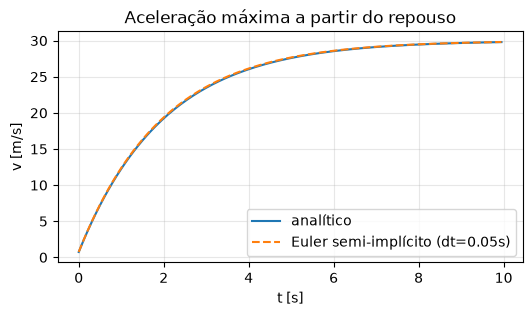

In [6]:
cfg = CONFIG["env"]
dt, k, a = cfg["dt"], cfg["k_drag"], cfg["a_max"]
t = np.arange(0, 10, dt)

p, v = np.zeros(2), np.zeros(2)
v_num = []
for _ in t:
    p, v = step_point_mass(p, v, np.array([a, 0.0]), dt, k)
    v_num.append(v[0])
v_num = np.array(v_num)
v_ana = a / k * (1 - np.exp(-k * (t + dt)))

print(f"velocidade terminal: {a / k:.1f} m/s | erro máximo da integração: {np.max(np.abs(v_num - v_ana)):.3f} m/s")
assert np.max(np.abs(v_num - v_ana)) < 0.5, "integração muito imprecisa!"

plt.figure(figsize=(6, 3))
plt.plot(t, v_ana, label="analítico")
plt.plot(t, v_num, "--", label=f"Euler semi-implícito (dt={dt}s)")
plt.xlabel("t [s]"); plt.ylabel("v [m/s]"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Aceleração máxima a partir do repouso")
plt.show()

## 4. A pista

Cada portão é definido por:
- `center`: posição do centro (m);
- `normal`: vetor unitário que diz **em que sentido** ele deve ser atravessado;
- `width`: abertura (m); `frame`: espessura das traves de cada lado (m). Encostar na trave é batida.

Para começar, colocamos 6 portões numa elipse, percorrida no sentido anti-horário.
A normal de cada portão é a tangente da elipse naquele ponto.
O parâmetro `jitter` (desligado por enquanto) deforma a pista aleatoriamente. Vamos usá-lo nos exercícios.

In [7]:
@dataclass
class Track:
    centers: np.ndarray   # (N, 2) posicao do centro de cada portao [m]
    normals: np.ndarray   # (N, 2) direcao em que o portao deve ser atravessado (unitario)
    width: float          # abertura do portao [m]
    frame: float          # espessura da "trave" de cada lado [m]

    @property
    def n_gates(self) -> int:
        return len(self.centers)


def make_ellipse_track(n_gates: int = 6, a: float = 20.0, b: float = 12.0,
                       width: float = 2.0, frame: float = 0.5,
                       jitter: float = 0.0, rng: np.random.Generator | None = None) -> Track:
    """Portoes espalhados numa elipse, atravessados no sentido anti-horario."""
    rng = rng if rng is not None else np.random.default_rng()
    theta = np.linspace(0.0, 2 * np.pi, n_gates, endpoint=False)
    r_scale = 1.0 + jitter * rng.uniform(-1, 1, size=n_gates)
    centers = np.stack([a * r_scale * np.cos(theta), b * r_scale * np.sin(theta)], axis=1)
    # tangente da elipse no sentido anti-horario: d/dtheta (a cos, b sin) = (-a sin, b cos)
    tangents = np.stack([-a * np.sin(theta), b * np.cos(theta)], axis=1)
    normals = tangents / np.linalg.norm(tangents, axis=1, keepdims=True)
    return Track(centers, normals, width, frame)

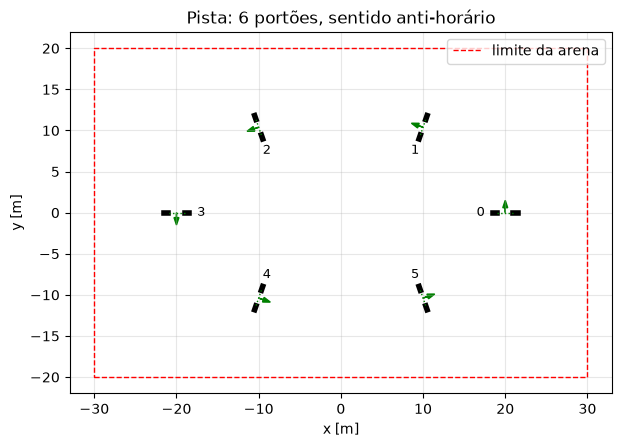

In [8]:
def plot_track(track: Track, ax=None, arena=None):
    ax = ax or plt.gca()
    for i, (c, n) in enumerate(zip(track.centers, track.normals)):
        t = np.array([-n[1], n[0]])                       # direção ao longo do portão
        w, f = track.width / 2, track.frame
        ax.plot(*np.stack([c + t * w, c + t * (w + f)]).T, "k-", lw=4)   # traves
        ax.plot(*np.stack([c - t * w, c - t * (w + f)]).T, "k-", lw=4)
        ax.plot(*np.stack([c + t * w, c - t * w]).T, "g:", lw=1)         # abertura
        ax.arrow(*c, *(1.5 * n), head_width=0.6, color="g", length_includes_head=True)
        ax.annotate(str(i), c + 2.0 * t * (w + f), ha="center", va="center", fontsize=9)
    if arena is not None:
        X, Y = arena
        ax.plot([-X, X, X, -X, -X], [-Y, -Y, Y, Y, -Y], "r--", lw=1, label="limite da arena")
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    return ax

track = make_ellipse_track(**CONFIG["env"]["track"])
plt.figure(figsize=(7, 5))
plot_track(track, arena=CONFIG["env"]["arena_half_size"]); plt.legend(loc="upper right")
plt.title("Pista: 6 portões, sentido anti-horário")
plt.show()

## 5. Atravessei o portão?

O truque é usar a **distância com sinal** até a reta do portão:

$$s = (\mathbf{p} - \mathbf{c}) \cdot \mathbf{n}$$

- $s < 0$: o drone está **antes** do portão; $s > 0$: **depois**.
- Num passo de simulação o drone vai de $\mathbf{p}_{prev}$ para $\mathbf{p}_{now}$. Se $s$ trocou de negativo para não-negativo, ele cruzou a reta.
- Interpolando, achamos o ponto exato de cruzamento e medimos o **deslocamento lateral** em relação ao centro.
  Dentro da abertura é passagem. Na trave é batida. Mais longe, ele só passou ao lado.

Verificar o **segmento** inteiro (e não só a posição final) é importante: a 30 m/s o drone anda 1.5 m por passo
e poderia "pular" um portão fino sem que nenhuma posição amostrada caísse dentro dele.

In [9]:
NO_CROSS, PASSED, HIT_FRAME = 0, 1, -1


def gate_crossing(p_prev: np.ndarray, p_now: np.ndarray, center: np.ndarray,
                  normal: np.ndarray, width: float, frame: float) -> int:
    """Verifica se o segmento p_prev -> p_now atravessou o portao.

    s = (p - c) . n  e a distancia com sinal ao "plano" (aqui, reta) do portao.
    Atravessar no sentido certo = s passa de negativo para >= 0.
    """
    s_prev = float((p_prev - center) @ normal)
    s_now = float((p_now - center) @ normal)
    if not (s_prev < 0.0 <= s_now):
        return NO_CROSS
    alpha = s_prev / (s_prev - s_now)              # fracao do passo onde cruzou
    p_cross = p_prev + alpha * (p_now - p_prev)
    tangent = np.array([-normal[1], normal[0]])
    lateral = abs(float((p_cross - center) @ tangent))
    if lateral <= width / 2:
        return PASSED
    if lateral <= width / 2 + frame:
        return HIT_FRAME
    return NO_CROSS

Testes rápidos com casos que sabemos a resposta. Um portão na origem, apontando para +x, com abertura de 2 m:

In [10]:
c, n = np.zeros(2), np.array([1.0, 0.0])
casos = {
    "passa pelo centro":            ((-1, 0.0), (1, 0.0), PASSED),
    "passa perto da borda (0.9 m)": ((-1, 0.9), (1, 0.9), PASSED),
    "bate na trave (1.2 m)":        ((-1, 1.2), (1, 1.2), HIT_FRAME),
    "passa ao lado (5 m)":          ((-1, 5.0), (1, 5.0), NO_CROSS),
    "sentido errado":               ((1, 0.0), (-1, 0.0), NO_CROSS),
    "não chega no portão":          ((-2, 0.0), (-1, 0.0), NO_CROSS),
    "cruza na diagonal":            ((-1, -1.5), (1, 1.5), PASSED),  # cruza em y=0
}
for nome, (p0, p1, esperado) in casos.items():
    r = gate_crossing(np.array(p0, float), np.array(p1, float), c, n, width=2.0, frame=0.5)
    print(f"{'✅' if r == esperado else '❌'} {nome:30s} -> {r}")
    assert r == esperado

✅ passa pelo centro              -> 1
✅ passa perto da borda (0.9 m)   -> 1
✅ bate na trave (1.2 m)          -> -1
✅ passa ao lado (5 m)            -> 0
✅ sentido errado                 -> 0
✅ não chega no portão            -> 0
✅ cruza na diagonal              -> 1


## 6. O ambiente Gymnasium

[Gymnasium](https://gymnasium.farama.org/) é a interface padrão entre ambientes e algoritmos de RL.
Qualquer classe que herde de `gym.Env` e implemente estes métodos funciona com o Stable-Baselines3:

| Membro | O que faz |
|---|---|
| `action_space` | formato e limites da ação. Aqui `Box(-1, 1, shape=(2,), float32)` |
| `observation_space` | formato da observação. Aqui `Box(-inf, inf, shape=(12,), float32)` |
| `reset(seed)` | começa um episódio novo e devolve `(obs, info)` |
| `step(action)` | avança um passo e devolve `(obs, reward, terminated, truncated, info)` |

### `terminated` vs `truncated`, uma diferença importante
- **`terminated`**: o episódio acabou por causa do próprio problema (bateu ou completou a corrida). Não há futuro.
- **`truncated`**: cortamos o episódio de forma artificial (limite de tempo). O futuro existiria.

O PPO usa essa diferença ao estimar o valor dos estados: num `truncated` ele ainda considera
a recompensa futura que o drone *teria* recebido. Confundir os dois atrapalha o aprendizado.

### Observação: o que a rede precisa saber?
Usamos grandezas **relativas ao drone**, e não posições absolutas na pista. Assim a política aprende
"o portão está 5 m à minha frente e um pouco à esquerda", o que generaliza para outras pistas.

| Índices | Conteúdo | Por quê |
|---|---|---|
| 0–1 | velocidade $\mathbf{v}$ / 10 | saber o quão rápido estou indo |
| 2–3 | (próximo portão − drone) / 10 | para onde ir agora |
| 4–5 | normal do próximo portão | de que lado entrar |
| 6–7 | (portão seguinte − próximo) / 10 | **planejar a curva** antes de chegar |
| 8–9 | normal do portão seguinte | idem |
| 10–11 | última ação | a penalidade de suavidade depende dela. Sem ela, o problema não seria Markoviano |

As divisões por 10 deixam os valores na ordem de grandeza de 1, que é a faixa em que redes neurais aprendem bem.

### Recompensa: o que queremos incentivar?
Seguimos a ideia de Song et al. (2021):

$$r_t = \underbrace{\lambda_p\,(d_{t-1} - d_t)}_{\text{progresso}} \;+\; \underbrace{\lambda_g\,\mathbb{1}[\text{passou}]}_{\text{portão}} \;-\; \underbrace{\lambda_c\,\mathbb{1}[\text{bateu}]}_{\text{batida}} \;-\; \lambda_a\,\|a_t\|^2 \;-\; \lambda_s\,\|a_t - a_{t-1}\|^2$$

onde $d_t$ é a distância até o próximo portão.
- O termo de **progresso** é uma recompensa *densa*: a cada passo o agente recebe uma dica de se está indo bem.
  Só com o bônus do portão (recompensa *esparsa*) o drone aleatório quase nunca acertaria um portão e não aprenderia nada.
- O **bônus do portão** e a **penalidade por bater** definem o objetivo de verdade.
- As penalidades de **ação** e **suavidade** evitam comandos "liga-desliga" que num drone real seriam impossíveis.

In [11]:
class PointMassRace2D(gym.Env):
    """Drone simplificado (ponto de massa 2D) correndo por uma pista de portoes."""

    metadata = {"render_modes": []}

    def __init__(self, cfg: dict):
        super().__init__()
        self.cfg = cfg
        self.dt = cfg["dt"]
        self.a_max = cfg["a_max"]
        self.k_drag = cfg["k_drag"]
        self.n_laps = cfg["n_laps"]
        self.max_steps = int(cfg["max_time"] / self.dt)
        self.arena = np.array(cfg["arena_half_size"], dtype=np.float64)
        self.track = make_ellipse_track(**cfg["track"])

        # acao: aceleracao normalizada em [-1, 1]^2  (shape (2,), float32)
        self.action_space = spaces.Box(-1.0, 1.0, shape=(2,), dtype=np.float32)
        # observacao: ver _get_obs  (shape (12,), float32)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(12,), dtype=np.float32)

    # ---------- helpers ----------
    def _gate(self, k: int) -> tuple[np.ndarray, np.ndarray]:
        i = (self.start_gate + k) % self.track.n_gates
        return self.track.centers[i], self.track.normals[i]

    def _get_obs(self) -> np.ndarray:
        c1, n1 = self._gate(self.gates_passed)
        c2, n2 = self._gate(self.gates_passed + 1)
        P, V = self.cfg["obs_pos_scale"], self.cfg["obs_vel_scale"]
        obs = np.concatenate([
            self.v / V,              # velocidade do drone
            (c1 - self.p) / P,       # onde esta o proximo portao (relativo ao drone)
            n1,                      # para onde ele "aponta"
            (c2 - c1) / P,           # o portao seguinte, relativo ao proximo
            n2,
            self.prev_action,        # ultima acao (necessaria p/ penalidade de suavidade)
        ])
        return obs.astype(np.float32)

    def _dist_to_next_gate(self) -> float:
        c, _ = self._gate(self.gates_passed)
        return float(np.linalg.norm(c - self.p))

    # ---------- API Gymnasium ----------
    def reset(self, *, seed: int | None = None, options: dict | None = None):
        super().reset(seed=seed)               # inicializa self.np_random
        if self.cfg["track"].get("jitter", 0.0) > 0:
            self.track = make_ellipse_track(**self.cfg["track"], rng=self.np_random)
        n = self.track.n_gates
        self.start_gate = int(self.np_random.integers(n)) if self.cfg["random_start_gate"] else 0
        c0, n0 = self._gate(0)
        # comeca parado alguns metros "antes" do primeiro portao, com ruido
        self.p = c0 - self.cfg["start_dist"] * n0 + self.np_random.normal(0, self.cfg["start_noise"], 2)
        self.v = np.zeros(2)
        self.prev_action = np.zeros(2)
        self.gates_passed = 0
        self.steps = 0
        self.prev_dist = self._dist_to_next_gate()
        return self._get_obs(), {}

    def step(self, action):
        action = np.clip(np.asarray(action, dtype=np.float64), -1.0, 1.0)
        rw = self.cfg["reward"]
        p_prev = self.p.copy()
        self.p, self.v = step_point_mass(self.p, self.v, self.a_max * action, self.dt, self.k_drag)
        self.steps += 1

        # 1) progresso: quanto me aproximei do portao-alvo neste passo
        dist = self._dist_to_next_gate()
        reward = rw["progress"] * (self.prev_dist - dist)
        # 2) penalidades de comando (gastar energia / mudar bruscamente)
        reward -= rw["action"] * float(action @ action)
        reward -= rw["smooth"] * float((action - self.prev_action) @ (action - self.prev_action))

        terminated, crashed, finished = False, False, False
        c, n = self._gate(self.gates_passed)
        result = gate_crossing(p_prev, self.p, c, n, self.track.width, self.track.frame)
        if result == PASSED:
            self.gates_passed += 1
            reward += rw["gate"]
            if self.gates_passed >= self.n_laps * self.track.n_gates:
                terminated, finished = True, True
        elif result == HIT_FRAME:
            terminated, crashed = True, True

        if np.any(np.abs(self.p) > self.arena):       # saiu da arena
            terminated, crashed = True, True
        if crashed:
            reward -= rw["crash"]

        truncated = (not terminated) and self.steps >= self.max_steps
        self.prev_dist = self._dist_to_next_gate()     # alvo pode ter mudado
        self.prev_action = action
        info = {"gates_passed": self.gates_passed, "crashed": crashed, "finished": finished,
                "time": self.steps * self.dt}
        return self._get_obs(), float(reward), terminated, truncated, info

O SB3 traz um `check_env` que testa se o ambiente segue a API corretamente (tipos, shapes, limites, seeds).
**Sempre rode isso** depois de escrever um ambiente novo.

In [12]:
from stable_baselines3.common.env_checker import check_env

env = PointMassRace2D(CONFIG["env"])
check_env(env)            # se algo estiver errado, ele levanta um erro explicando
obs, info = env.reset(seed=0)
print("action_space     :", env.action_space)
print("observation_space:", env.observation_space)
print("obs              :", obs.shape, obs.dtype, np.round(obs, 2))

action_space     : Box(-1.0, 1.0, (2,), float32)
observation_space: Box(-inf, inf, (12,), float32)
obs              : (12,) float32 [ 0.    0.    0.38  0.1   0.94  0.33  1.    1.04 -0.    1.    0.    0.  ]


## 7. Linha de base: um agente aleatório

Antes de treinar, vamos ver o que acontece com ações aleatórias. Isso dá uma referência
("o que é ruim?") e ajuda a pegar bugs no ambiente.

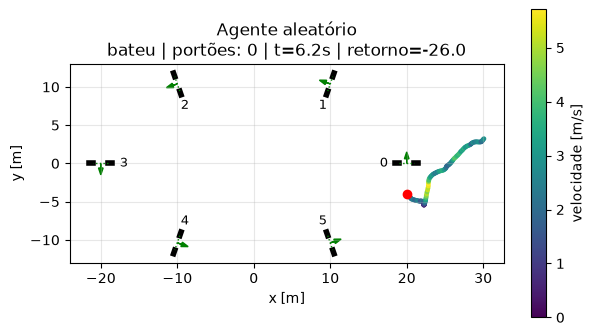

In [13]:
def run_episode(env: gym.Env, policy, seed: int | None = None) -> dict:
    # Roda um episódio. `policy(obs) -> action`. Devolve trajetória e métricas.
    obs, _ = env.reset(seed=seed)
    traj, speeds, total_r, done = [env.p.copy()], [0.0], 0.0, False
    while not done:
        obs, r, terminated, truncated, info = env.step(policy(obs))
        traj.append(env.p.copy()); speeds.append(np.linalg.norm(env.v))
        total_r += r
        done = terminated or truncated
    return {"traj": np.array(traj), "speed": np.array(speeds), "return": total_r, **info}


def plot_episode(ep: dict, track: Track, ax=None, title=""):
    ax = ax or plt.gca()
    plot_track(track, ax)
    sc = ax.scatter(*ep["traj"].T, c=ep["speed"], cmap="viridis", s=6, vmin=0)
    ax.plot(*ep["traj"][0], "ro", label="início")
    plt.colorbar(sc, ax=ax, label="velocidade [m/s]", shrink=0.8)
    status = "completou" if ep["finished"] else ("bateu" if ep["crashed"] else "tempo esgotado")
    ax.set_title(f"{title}\n{status} | portões: {ep['gates_passed']} | t={ep['time']:.1f}s | retorno={ep['return']:.1f}")
    return ax


eval_env = PointMassRace2D(dict(CONFIG["env"], random_start_gate=False))
eval_env.action_space.seed(0)
ep_rand = run_episode(eval_env, lambda o: eval_env.action_space.sample(), seed=0)
plt.figure(figsize=(7, 5)); plot_episode(ep_rand, eval_env.track, title="Agente aleatório"); plt.show()

## 8. Treinando com PPO

### Intuição do PPO
O PPO (*Proximal Policy Optimization*) é um método **ator-crítico**:
- O **ator** $\pi_\theta(a|o)$ é uma rede que gera uma distribuição Gaussiana sobre as ações (média e desvio).
  No começo o desvio é grande, então o agente explora bastante. Com o tempo ele fica mais confiante.
- O **crítico** $V_\phi(o)$ é uma rede que estima o retorno esperado a partir de uma observação.
  Ele serve para calcular a **vantagem** $A_t$: "essa ação foi melhor ou pior do que eu esperava?"

O ciclo de treino é:
1. Rodar a política atual por `n_steps` passos em cada um dos `n_envs` ambientes (8 × 512 = 4096 transições).
2. Calcular as vantagens com GAE ($\gamma$, $\lambda$).
3. Atualizar as redes por `n_epochs` épocas em mini-batches de `batch_size`, tornando ações com vantagem positiva mais prováveis.
   O **clip** impede que a política nova se afaste demais da antiga num único passo, e é daí que vem a estabilidade do PPO.

### Por que vários ambientes em paralelo?
Com 8 cópias do ambiente coletamos experiências mais variadas por atualização (menos correlação) e aproveitamos melhor a CPU.
`make_vec_env` empilha as observações num array de shape `(n_envs, 12)`.

### CPU ou GPU?
Para MLPs pequenas como esta, **a CPU é mais rápida**, porque o gargalo é simular o ambiente e não a rede.
Por isso usamos `device="cpu"`.

In [14]:
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor

train_env = make_vec_env(lambda: PointMassRace2D(CONFIG["env"]),
                         n_envs=CONFIG["n_envs"], seed=CONFIG["seed"])

# Ambiente de avaliação: sempre começa no portão 0 (para comparar treinos de forma justa)
eval_cfg = dict(CONFIG["env"], random_start_gate=False)
eval_callback = EvalCallback(
    Monitor(PointMassRace2D(eval_cfg)),
    eval_freq=max(CONFIG["eval_freq"] // CONFIG["n_envs"], 1),  # eval_freq é contado por ambiente
    n_eval_episodes=5,
    deterministic=True,                      # na avaliação usamos a média da Gaussiana, sem ruído
    best_model_save_path=str(RUN_DIR),
    log_path=str(RUN_DIR),
    verbose=0,
)

model = PPO(
    "MlpPolicy", train_env,
    policy_kwargs=dict(net_arch=dict(pi=CONFIG["net_arch"], vf=CONFIG["net_arch"])),
    seed=CONFIG["seed"], device="cpu", verbose=0,
    tensorboard_log=str(RUN_DIR / "tb"),
    **CONFIG["ppo"],
)
print(model.policy)

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=12, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=12, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=128, out_features=2, bias=True)
  (value_net): Linear(in_features=128, out_features=1, bias=True)
)


### Callbacks: gravando o treino para visualizar depois

Um **callback** é um código que o SB3 chama durante o treino (a cada passo, a cada rollout etc.).
Além do `EvalCallback`, vamos usar mais dois para a seção 10:

- `CheckpointCallback`: salva uma cópia da política a cada `checkpoint_every` passos.
  Depois colocamos essas versões "de diferentes idades" para correr juntas.
- `TrainingDronesRecorder` (escrito abaixo): em alguns momentos do treino, grava a posição dos
  **8 drones de treino** por alguns segundos.

Repare: os 8 ambientes paralelos são **8 drones controlados pela mesma rede neural** (um cérebro, oito corpos).
Durante o treino eles usam a política **estocástica** (com ruído de exploração) e começam em portões aleatórios,
por isso cada um faz uma coisa diferente.

In [15]:
from stable_baselines3.common.callbacks import BaseCallback, CheckpointCallback


class TrainingDronesRecorder(BaseCallback):
    # Grava a posição dos n_envs drones de treino em algumas janelas do treinamento.

    def __init__(self, record_at_steps: list[int], window: int):
        super().__init__()
        self.pending = sorted(record_at_steps)
        self.window = window
        self.recordings: list[dict] = []   # cada uma: step, pos (T, n_envs, 2), done (T, n_envs)
        self._cur = None

    def _on_step(self) -> bool:
        if self._cur is None and self.pending and self.num_timesteps >= self.pending[0]:
            self.pending.pop(0)
            self._cur = {"step": self.num_timesteps, "pos": [], "done": []}
        if self._cur is not None:
            # get_attr lê um atributo de cada ambiente do VecEnv -> lista de n_envs arrays (2,)
            self._cur["pos"].append(np.array(self.training_env.get_attr("p")))
            self._cur["done"].append(np.array(self.locals["dones"]))   # (n_envs,) bool
            if len(self._cur["pos"]) >= self.window:
                self.recordings.append({"step": self._cur["step"],
                                        "pos": np.array(self._cur["pos"]),
                                        "done": np.array(self._cur["done"])})
                self._cur = None
        return True  # False interromperia o treino


viz = CONFIG["viz"]
checkpoint_cb = CheckpointCallback(save_freq=viz["checkpoint_every"] // CONFIG["n_envs"],
                                   save_path=str(RUN_DIR / "checkpoints"), name_prefix="ppo")
recorder = TrainingDronesRecorder([int(f * CONFIG["total_timesteps"]) for f in viz["record_fracs"]],
                                  window=viz["record_window"])

Agora o treino de fato. A barra de progresso mostra os passos.

> 💡 Se quiser acompanhar as curvas **durante** o treino, rode a célula do TensorBoard (logo abaixo) antes desta.

In [16]:
t0 = time.time()
model.learn(total_timesteps=CONFIG["total_timesteps"],
            callback=[eval_callback, checkpoint_cb, recorder], progress_bar=True)
print(f"Treino concluído em {(time.time() - t0) / 60:.1f} min")
model.save(RUN_DIR / "final_model")

Treino concluído em 1.2 min


### Monitorando o treino

O SB3 grava logs para o **TensorBoard**. As curvas mais úteis são:
- `rollout/ep_rew_mean`: retorno médio por episódio (deve subir);
- `rollout/ep_len_mean`: duração dos episódios (sobe enquanto o drone aprende a não bater e depois cai quando ele fica rápido);
- `train/approx_kl` e `train/clip_fraction`: o tamanho das atualizações. Se ficarem muito altos, reduza o `learning_rate`;
- `train/explained_variance`: o quanto o crítico acerta (perto de 1 é bom).

No Colab ou no Jupyter local, rode:

In [17]:
SHOW_TENSORBOARD = IN_COLAB    # mude para True para abrir localmente também
if SHOW_TENSORBOARD:
    %load_ext tensorboard
    %tensorboard --logdir runs

Também podemos plotar as avaliações periódicas que o `EvalCallback` salvou em `evaluations.npz`:

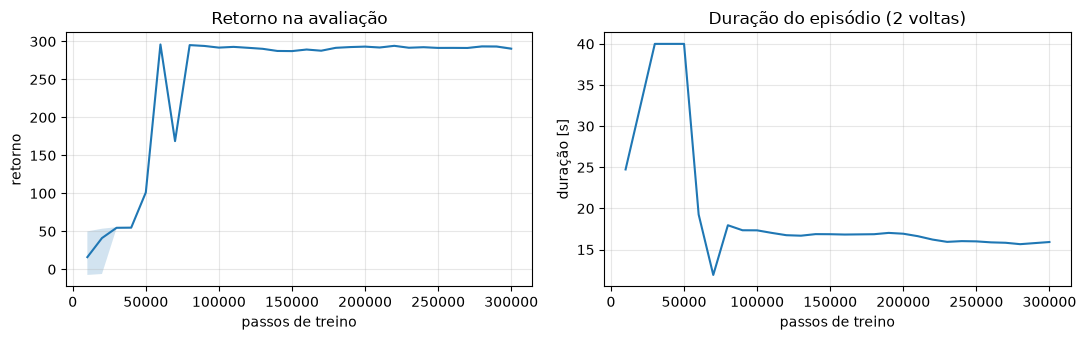

In [18]:
ev = np.load(RUN_DIR / "evaluations.npz")
steps, R = ev["timesteps"], ev["results"]          # R: (n_avaliações, n_eval_episodes)
L = ev["ep_lengths"] * CONFIG["env"]["dt"]          # duração em segundos

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(steps, R.mean(1)); axs[0].fill_between(steps, R.min(1), R.max(1), alpha=0.2)
axs[0].set_xlabel("passos de treino"); axs[0].set_ylabel("retorno"); axs[0].set_title("Retorno na avaliação")
axs[1].plot(steps, L.mean(1)); axs[1].set_xlabel("passos de treino"); axs[1].set_ylabel("duração [s]")
axs[1].set_title("Duração do episódio (2 voltas)")
for a in axs: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Avaliação

Vamos carregar o **melhor modelo** salvo pelo `EvalCallback` e rodar alguns episódios com
seeds diferentes (a posição inicial tem ruído). Métricas:
- **taxa de sucesso**: completou as 2 voltas sem bater;
- **tempo por volta**.

sucesso: 20/20 | batidas: 0
tempo por volta: 9.63 ± 0.02 s | velocidade máxima: 14.6 m/s


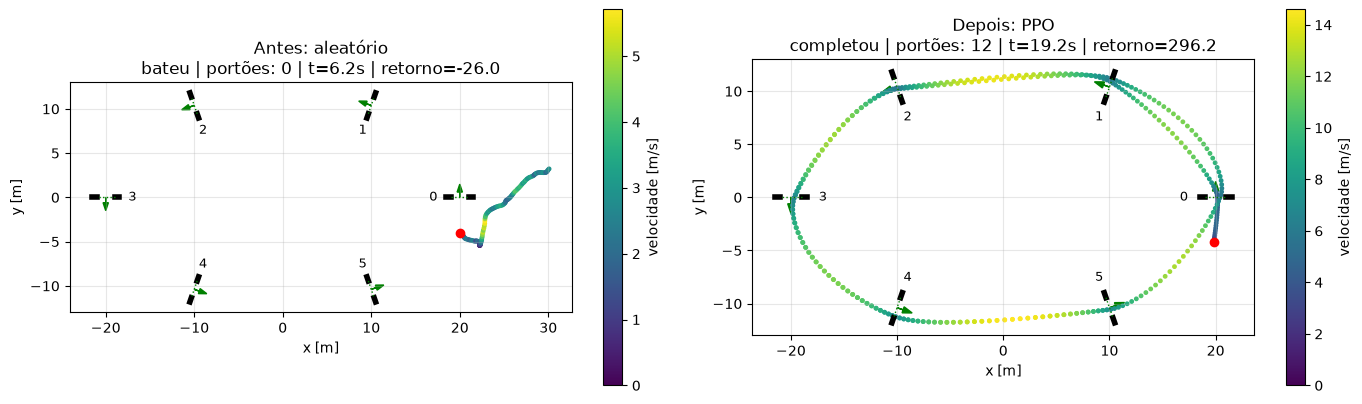

In [19]:
best = PPO.load(RUN_DIR / "best_model", device="cpu")
policy = lambda o: best.predict(o, deterministic=True)[0]

episodes = [run_episode(eval_env, policy, seed=1000 + i) for i in range(20)]
succ = [e for e in episodes if e["finished"]]
print(f"sucesso: {len(succ)}/{len(episodes)} | batidas: {sum(e['crashed'] for e in episodes)}")
if succ:
    lap = np.array([e["time"] for e in succ]) / CONFIG["env"]["n_laps"]
    vmax = np.max([e["speed"].max() for e in succ])
    print(f"tempo por volta: {lap.mean():.2f} ± {lap.std():.2f} s | velocidade máxima: {vmax:.1f} m/s")

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
plot_episode(ep_rand, eval_env.track, axs[0], title="Antes: aleatório")
plot_episode(episodes[0], eval_env.track, axs[1], title="Depois: PPO")
plt.tight_layout(); plt.show()

Repare nas cores: o drone **acelera nas retas e freia antes das curvas mais fechadas** (nas pontas da elipse).
Ninguém programou isso. A estratégia surgiu só da recompensa de progresso combinada com o desconto $\gamma$.

### Animação

Vamos escrever uma função de animação genérica, que desenha **N drones em um ou mais painéis**.
Ela serve para um drone só (agora) e para vários drones (na próxima seção).
Cada drone é desenhado com um rastro curto. Ao terminar, vira ★ se completou a corrida ou ✖ se bateu.

> As animações usam `to_jshtml()`, que gera um player dentro do notebook (funciona no Colab e no Jupyter).
> Renderizar todos os quadros leva alguns segundos.

In [ ]:
from matplotlib import animation
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 100   # MB. O padrão (20 MB) cortaria as animações maiores


def animate_panels(panels: list[dict], track: Track, dt: float, skip: int = 2, tail: int = 40,
                   ncols: int | None = None, panel_size=(5.0, 3.8), suptitle: str = ""):
    # Anima N drones por painel. Cada painel é um dict com:
    #   pos    : (T, N, 2) posições [m]
    #   ep_id  : (T, N) int, opcional. Muda quando o drone reinicia o episódio (o rastro é cortado)
    #   ended  : (T, N) int, opcional. 0 = correndo, 1 = completou, -1 = bateu
    #   colors, labels : listas de N itens, opcionais
    #   title  : título do painel
    n = len(panels)
    ncols = ncols or min(n, 3)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
                            squeeze=False, dpi=80)
    T = max(p["pos"].shape[0] for p in panels)
    state = []
    for ax, pnl in zip(axs.flat, panels):
        pos = pnl["pos"]
        Tp, N, _ = pos.shape
        ep_id = pnl.get("ep_id", np.zeros((Tp, N), int))
        ended = pnl.get("ended", np.zeros((Tp, N), int))
        colors = pnl.get("colors") or [plt.cm.tab10(j % 10) for j in range(N)]
        labels = pnl.get("labels") or [None] * N
        X, Y = CONFIG["env"]["arena_half_size"]
        plot_track(track, ax, arena=(X, Y))
        ax.set_xlim(-X - 1, X + 1); ax.set_ylim(-Y - 1, Y + 1)   # fixo: mostra quem sai da arena
        ax.set_title(pnl.get("title", ""), fontsize=10)
        trails = [ax.plot([], [], "-", color=colors[j], lw=1.5, alpha=0.6)[0] for j in range(N)]
        dots = [ax.plot([], [], "o", color=colors[j], ms=7, mec="k", mew=0.5, label=labels[j])[0]
                for j in range(N)]
        if pnl.get("labels"):
            ax.legend(loc="center", fontsize=8, framealpha=0.7)
        state.append((pos, ep_id, ended, trails, dots))
    for ax in axs.flat[n:]:
        ax.axis("off")
    header = fig.suptitle("")
    fig.tight_layout()

    def update(i):
        k = i * skip
        for pos, ep_id, ended, trails, dots in state:
            kk = min(k, len(pos) - 1)
            lo = max(0, kk - tail)
            for j, (tr, dot) in enumerate(zip(trails, dots)):
                same_ep = ep_id[lo:kk + 1, j] == ep_id[kk, j]      # não liga pontos de episódios diferentes
                tr.set_data(*pos[lo:kk + 1, j][same_ep].T)
                dot.set_data([pos[kk, j, 0]], [pos[kk, j, 1]])
                e = ended[kk, j]
                dot.set_marker({1: "*", -1: "X"}.get(e, "o"))
                dot.set_markersize({1: 15, -1: 10}.get(e, 7))
        header.set_text(f"{suptitle}   t = {k * dt:.1f} s")

    anim = animation.FuncAnimation(fig, update, frames=(T - 1) // skip + 1, interval=1000 * dt * skip)
    plt.close(fig)
    return anim


def show_animation(anim, name: str):
    # Mostra no notebook e (opcional) salva um GIF em RUN_DIR para compartilhar.
    if CONFIG["viz"]["save_gifs"]:
        anim.save(RUN_DIR / f"{name}.gif", writer=animation.PillowWriter(fps=10))
    return HTML(anim.to_jshtml())


ep = episodes[0]
status = np.zeros((len(ep["traj"]), 1), int)
status[-1] = 1 if ep["finished"] else (-1 if ep["crashed"] else 0)
anim = animate_panels([{"pos": ep["traj"][:, None, :], "ended": status, "colors": ["red"]}],
                      eval_env.track, CONFIG["env"]["dt"], tail=60, panel_size=(7, 5),
                      suptitle="PPO treinado")
show_animation(anim, "corrida_ppo")

## 10. Visualizando o aprendizado com vários drones

### 10.1 Os 8 drones de treino ao longo do tempo

Estes são os drones que **geraram os dados de treino**, gravados pelo `TrainingDronesRecorder` em
cinco momentos. Cada cor é um dos 8 ambientes paralelos. Quando um drone bate ou termina,
o ambiente reinicia sozinho (*auto-reset*) e ele reaparece em outro portão.

O que observar:
- **No início** os movimentos são aleatórios: a rede ainda não sabe nada e o ruído de exploração domina.
- **Depois** os drones aprendem a ir até o portão, mas ainda batem nas traves ou saem da arena.
- **No fim** todos dão a volta de forma consistente, mesmo com o ruído de exploração ligado.

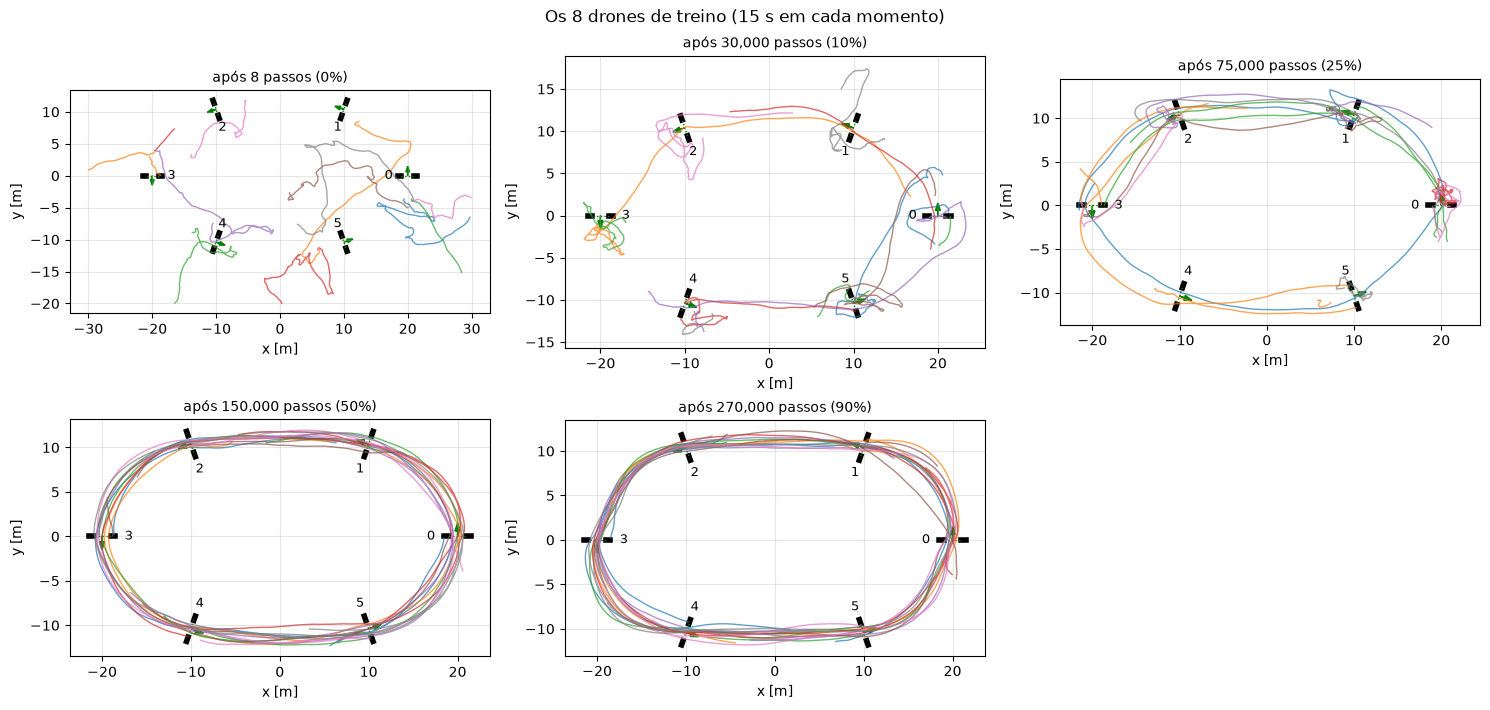

In [21]:
def recording_panel(rec: dict) -> dict:
    ep_id = np.cumsum(rec["done"], axis=0)          # (T, n_envs): incrementa a cada reset
    return {"pos": rec["pos"], "ep_id": ep_id,
            "title": f"após {rec['step']:,} passos ({rec['step'] / CONFIG['total_timesteps']:.0%})"}


train_panels = [recording_panel(r) for r in recorder.recordings]

# Versão estática: o rastro completo de cada janela
fig, axs = plt.subplots(2, 3, figsize=(15, 7.2))
for ax, pnl in zip(axs.flat, train_panels):
    plot_track(eval_env.track, ax)
    for j in range(pnl["pos"].shape[1]):
        xy = pnl["pos"][:, j].copy()
        xy[1:][np.diff(pnl["ep_id"][:, j]) > 0] = np.nan   # corta o traço no reset
        ax.plot(*xy.T, "-", color=plt.cm.tab10(j), lw=1, alpha=0.7)
    ax.set_title(pnl["title"], fontsize=10)
for ax in axs.flat[len(train_panels):]:
    ax.axis("off")
fig.suptitle(f"Os {CONFIG['n_envs']} drones de treino ({CONFIG['viz']['record_window'] * CONFIG['env']['dt']:.0f} s em cada momento)")
plt.tight_layout(); plt.show()

E a versão animada, com todos os momentos rodando ao mesmo tempo:

In [ ]:
anim = animate_panels(train_panels, eval_env.track, CONFIG["env"]["dt"], skip=3, tail=30,
                      suptitle=f"{CONFIG['n_envs']} drones de treino (mesma rede, com ruído de exploração)")
show_animation(anim, "drones_de_treino")

### 10.2 Corrida de fantasmas: a mesma rede em diferentes "idades"

Agora carregamos os checkpoints salvos durante o treino e colocamos todos para correr **juntos, na mesma pista,
saindo do mesmo ponto**, como os "fantasmas" de um jogo de corrida. Aqui usamos a política **determinística**
(sem ruído), ou seja, o que cada versão realmente aprendeu.

Os drones não colidem entre si: cada um roda no seu próprio ambiente e só desenhamos todos juntos.

    25k passos: tempo esgotado portões= 2  t=40.0s
    50k passos: tempo esgotado portões= 4  t=40.0s
   100k passos: completou      portões=12  t=17.3s
   200k passos: completou      portões=12  t=16.9s
  final (300k): completou      portões=12  t=15.7s


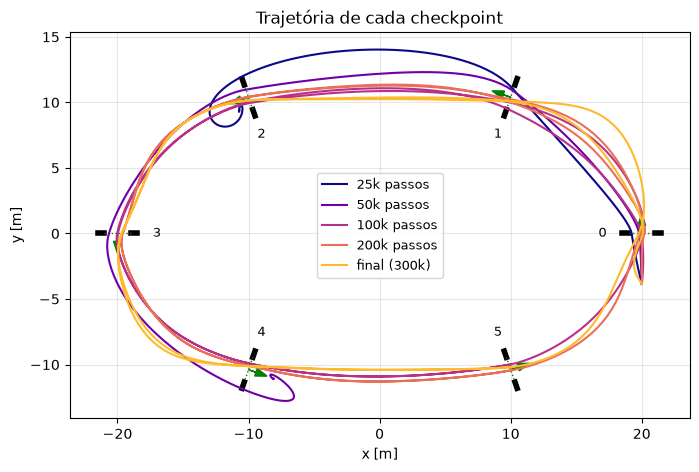

In [23]:
def race(policies: list, env: gym.Env, seed: int, max_time: float) -> tuple[np.ndarray, np.ndarray, list]:
    # Cada política corre sozinha com a mesma seed (mesma posição inicial). Junta tudo em (T, N, 2).
    eps = [run_episode(env, pol, seed=seed) for pol in policies]
    T = min(max(len(e["traj"]) for e in eps), int(max_time / env.dt))
    pos = np.zeros((T, len(eps), 2))
    ended = np.zeros((T, len(eps)), int)
    for j, e in enumerate(eps):
        L = min(len(e["traj"]), T)
        pos[:L, j] = e["traj"][:L]
        pos[L:, j] = e["traj"][L - 1]                  # fica parado onde terminou
        if L == len(e["traj"]):
            ended[L - 1:, j] = 1 if e["finished"] else (-1 if e["crashed"] else 0)
    return pos, ended, eps


ghosts = [(f"{s // 1000}k passos", PPO.load(RUN_DIR / "checkpoints" / f"ppo_{s}_steps", device="cpu"))
          for s in CONFIG["viz"]["ghost_steps"]]
ghosts.append((f"final ({CONFIG['total_timesteps'] // 1000}k)", model))
labels = [name for name, _ in ghosts]
policies = [(lambda o, m=m: m.predict(o, deterministic=True)[0]) for _, m in ghosts]
colors = [plt.cm.plasma(x) for x in np.linspace(0.0, 0.85, len(ghosts))]

pos, ended, ghost_eps = race(policies, eval_env, seed=7, max_time=25.0)
for name, e in zip(labels, ghost_eps):
    status = "completou" if e["finished"] else ("bateu" if e["crashed"] else "tempo esgotado")
    print(f"{name:>14s}: {status:14s} portões={e['gates_passed']:2d}  t={e['time']:.1f}s")

plt.figure(figsize=(8, 5.5))
plot_track(eval_env.track)
for j, (name, c) in enumerate(zip(labels, colors)):
    plt.plot(*ghost_eps[j]["traj"].T, "-", color=c, lw=1.5, label=name)
plt.legend(loc="center", fontsize=9); plt.title("Trajetória de cada checkpoint")
plt.show()

In [ ]:
anim = animate_panels([{"pos": pos, "ended": ended, "colors": colors, "labels": labels}],
                      eval_env.track, CONFIG["env"]["dt"], tail=50, panel_size=(8, 5.5),
                      suptitle="Corrida de fantasmas")
show_animation(anim, "corrida_de_fantasmas")

> 💾 Com `viz.save_gifs = True`, os GIFs ficam em `RUN_DIR` (no Colab, abra o painel de arquivos à esquerda
> para baixar). Ótimo para colocar no README ou mostrar para alguém.

Nas próximas etapas vamos para o 3D. Lá a visualização vai ganhar a atitude do drone (para onde ele está inclinado).

## 11. Salvando e carregando

O modelo fica em `runs/.../final_model.zip` e `best_model.zip`, junto com o `config.json`.

> ⚠️ **No Colab, os arquivos somem quando a sessão termina.** Para guardar, monte o Google Drive:
> ```python
> from google.colab import drive
> drive.mount("/content/drive")
> !cp -r runs /content/drive/MyDrive/dronerl_runs
> ```

Um teste rápido de que salvar e carregar preserva a política:

In [25]:
loaded = PPO.load(RUN_DIR / "final_model", device="cpu")
obs_batch = np.stack([eval_env.observation_space.sample() for _ in range(32)])   # (32, 12) float32
a1, _ = model.predict(obs_batch, deterministic=True)
a2, _ = loaded.predict(obs_batch, deterministic=True)
assert np.allclose(a1, a2), "modelo carregado difere!"
print("✅ modelo salvo e carregado gera as mesmas ações. shape:", a1.shape, a1.dtype)

✅ modelo salvo e carregado gera as mesmas ações. shape: (32, 2) float32


## 12. Exercícios (para fixar)

Mude **uma coisa por vez** no `CONFIG`, treine de novo e compare com o resultado acima.

1. **Sem suavidade**: `reward.smooth = 0` e `reward.action = 0`. Como fica a trajetória? E as ações?
   (dica: plote as ações ao longo do episódio)
2. **Desconto**: compare `gamma = 0.9` e `gamma = 0.999`. Qual fica mais rápido? Qual aprende mais rápido? Por quê?
3. **Visão curta**: remova o "portão seguinte" da observação (índices 6–9). O drone ainda faz as curvas bem?
4. **Generalização**: treine com `track.jitter = 0.3` (pistas aleatórias a cada episódio) e avalie numa pista nova.
5. **Recompensa esparsa**: zere `reward.progress`. O agente consegue aprender?
6. **Outro algoritmo**: troque `PPO` por `SAC` (`from stable_baselines3 import SAC`). Ele é *off-policy* e costuma
   precisar de menos amostras, mas cada passo é mais caro. Compare o tempo de relógio e o número de passos.

## Próxima etapa

Na **Etapa 2** saímos do ponto de massa e escrevemos a dinâmica de um **quadrotor 3D**: corpo rígido, quaternions,
empuxo coletivo e velocidades angulares como ação, que é o mesmo tipo de comando usado pelos trabalhos que
venceram pilotos humanos. Também vamos verificar numericamente as convenções de frames (ENU/FLU).